# CA3 - Classification of Wine

#### Gr 30: Sondre Aasheim & Zuzanna Magdalena Smolinska

### Imports

In [3]:
import numpy as np                      # for numerical operations
import pandas as pd                     # for reading the csv files and working with dataframes
import matplotlib.pyplot as plt         # for basic plotting
import seaborn as sns                   # for more advanced plotting

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import warnings 
warnings.filterwarnings('ignore')


### Reading the data

We use the provided files: `train.csv`  - containing 835 labelled wines that we use to train our models, and `test.csv` - containing 209 unlabelled wines that we use for the predicttion for the Kaggle Competition

In [4]:
# reading the data (both files must be in the same folder as this notebook)
wine_train = pd.read_csv("train.csv")
wine_test = pd.read_csv("test.csv")
 
# printing the training data to get a look
print("Train shape:", wine_train.shape)
print("Test shape: ", wine_test.shape)
wine_train.head()

Train shape: (835, 13)
Test shape:  (209, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.8,0.610,0.29,1.6,0.114,9.0,29.0,0.99740,3.26,1.56,9.1,0,13
1,8.4,1.035,0.15,6.0,0.073,11.0,54.0,0.99900,3.37,0.49,9.9,0,705
2,8.1,0.290,0.36,2.2,0.048,35.0,53.0,0.99500,3.27,1.01,12.4,1,1408
3,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,1,144
4,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,0,557


In [5]:
# to double check that we have the right files, and to display their size (rows, columns)
print("Training data size: ", wine_train.shape)
print("Test data size: ", wine_test.shape)

# list of all column names in the training data
print(wine_train.columns.tolist())


Training data size:  (835, 13)
Test data size:  (209, 12)
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']


### Data exploration and visualisation

In [6]:
# To get a greater overview over the data
wine_train.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000
mean,8.310898,0.540042,0.260790,2.542994,0.088674,15.859880,47.077246,0.996799,3.308707,0.658048,10.396287,0.500599,800.470659
std,1.757359,0.179786,0.197739,1.420451,0.051485,10.444733,33.271056,0.001946,0.159072,0.179891,1.087407,0.500299,468.873363
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,7.000000,0.990070,2.740000,0.330000,8.400000,0.000000,0.000000
25%,7.100000,0.410000,0.080000,1.900000,0.071000,7.000000,22.000000,0.995600,3.200000,0.550000,9.500000,0.000000,408.000000
50%,7.900000,0.540000,0.240000,2.200000,0.080000,13.000000,38.000000,0.996750,3.310000,0.610000,10.100000,1.000000,784.000000
75%,9.100000,0.647500,0.410000,2.600000,0.091000,21.000000,63.000000,0.997900,3.400000,0.725000,11.000000,1.000000,1225.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,1.000000,1597.000000


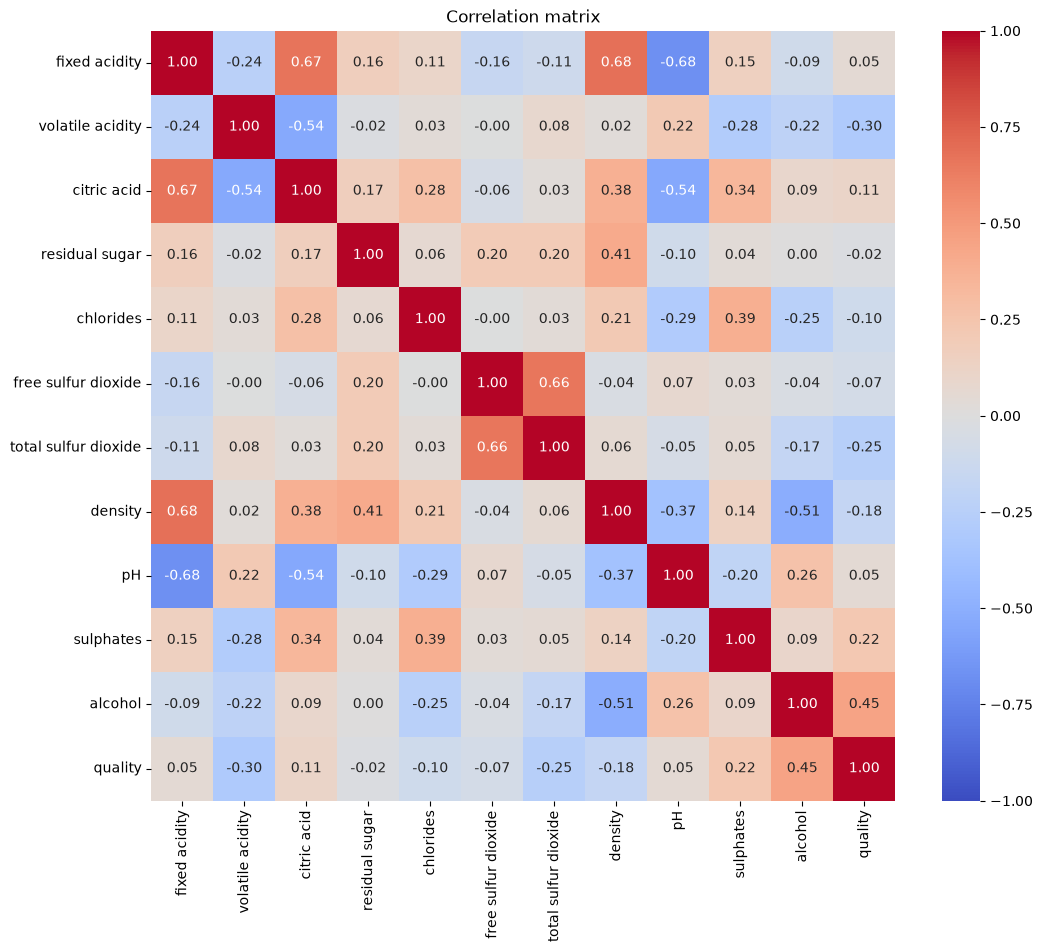

In [139]:
# correlation heatmap: how strongly each feature is related to quality and to each other

corr = wine_train[features + ["quality"]].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

### Data cleaning

In [140]:
# counting all missing values in the training and test data
# this should give 0, so there are no missing numbers or information

print(wine_train.isna().sum().sum())
print(wine_test.isna().sum().sum())

0
0


### Data preprocessing and visualisation

In [7]:
# first scaling the feauterses 
features =['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
  'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates',
    'alcohol']

# Setting the scaling method, alternative is MinMaxScaler
scaler = StandardScaler()

# scaling the training date
wine_train_sc = wine_train.copy()
wine_train_sc[features] = scaler.fit_transform(wine_train[features])

# Scaling the test data
wine_test_scaled_sc = wine_test.copy()
wine_test_scaled_sc[features] = scaler.transform(wine_test[features])

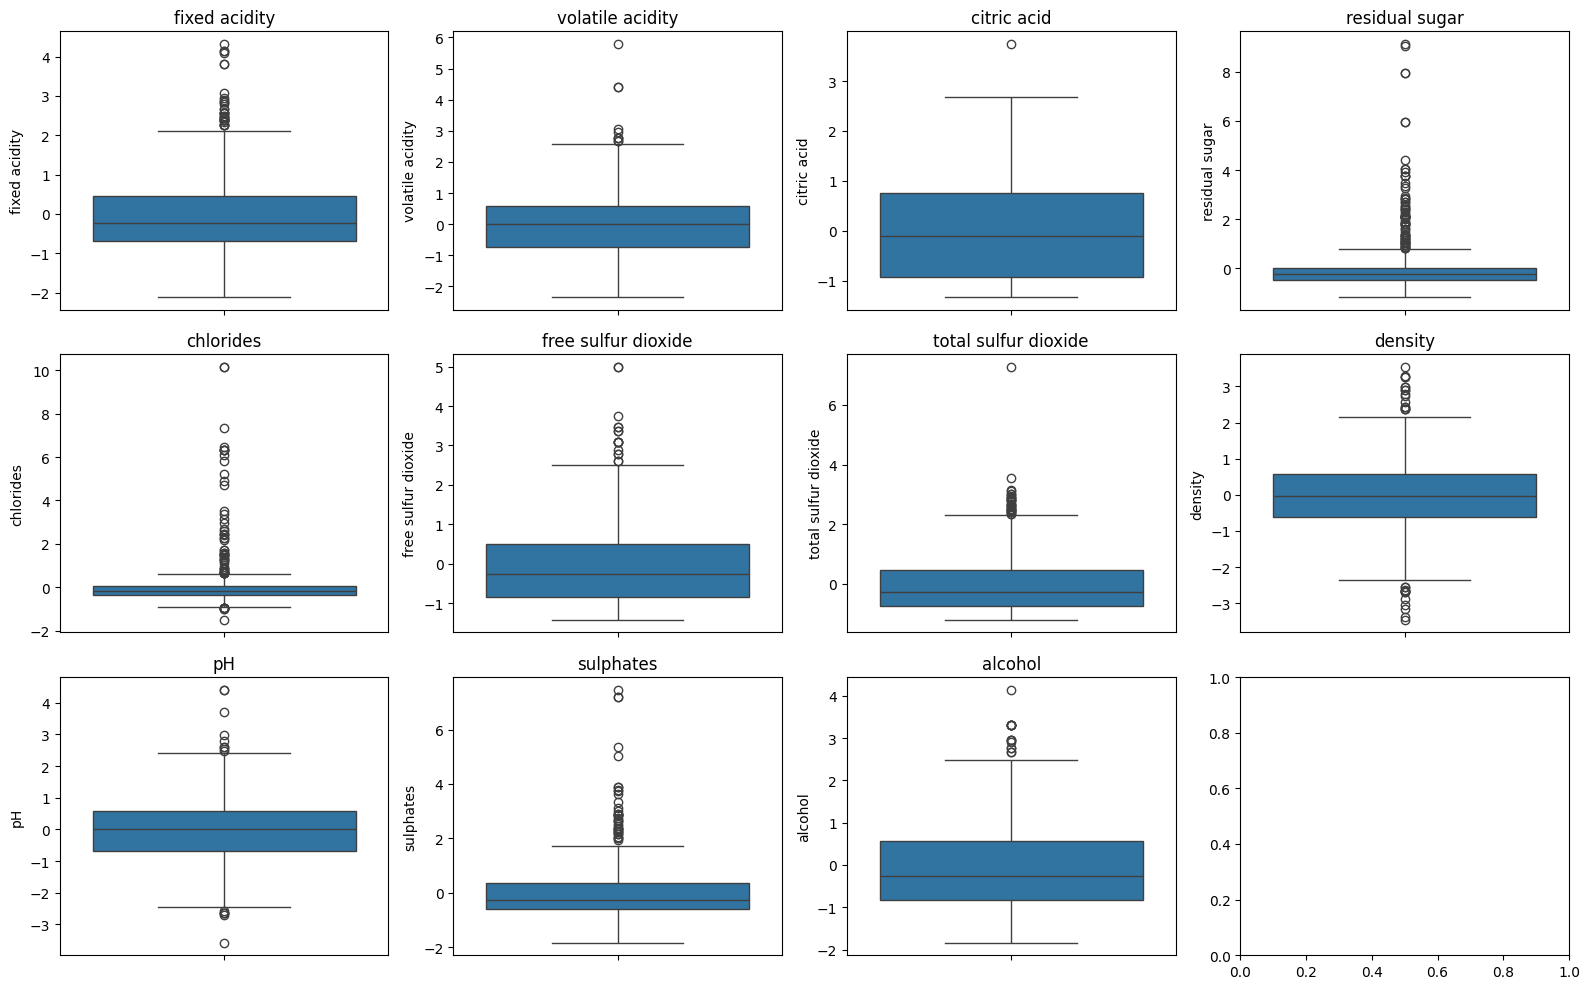

In [8]:
# Displaying the outliers by directly showing where different samples cluster together, and by extension the outliers
fig, axes = plt.subplots(3, 4, figsize=(16, 10))


for ax, col in zip(axes.flat, features):
    sns.boxplot(data=wine_train_sc, y=col, ax=ax)
    ax.set_title(col)


plt.tight_layout()
plt.show()


As can be seen in the boxes, a lot of the data, even most if not all of some feautures falls outside of the "average" meaning removing the outliers will be harder than just removing those that fall outside the average. As there are still clear outliers.


**Discusion**:
In regards to outliers, there can be made an argument that in this instance it would be unecasary to remove them. As we do not know the standards of which these tests were carried out in. Or if these outliers are even that far fetched in regards to bigger samples of wine. They would also simply be filed away into the lower quality catagori if kept. 

In [9]:
# Gives each item inside the dataframe a score based on how far it is from the mean through z = (x-mu)/sigma
z_scores = (wine_train_sc - wine_train_sc.mean()) / wine_train_sc.std(ddof=0)

# Checks if the z score is above or under the average by 3 through using absolute values
outliers = z_scores.abs() > 3

# Checking to see where the outliers are found
print("Outliers per feature:")
print(outliers.sum())

Outliers per feature:
fixed acidity            7
volatile acidity         4
citric acid              1
residual sugar          16
chlorides               16
free sulfur dioxide     11
total sulfur dioxide     6
density                  8
pH                       4
sulphates               13
alcohol                  7
quality                  0
Id                       0
dtype: int64


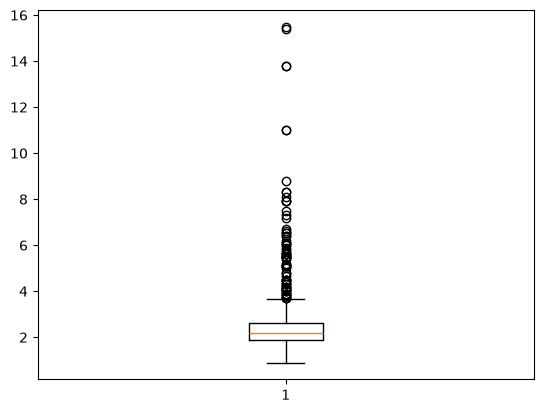

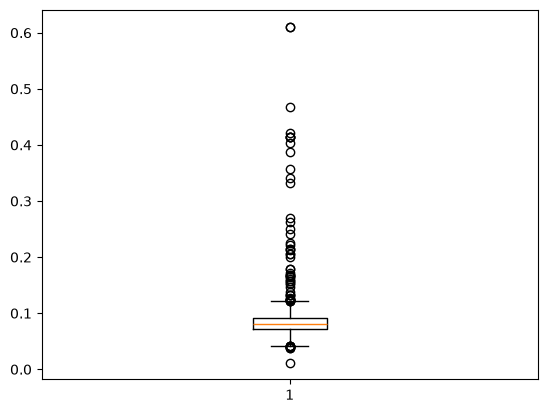

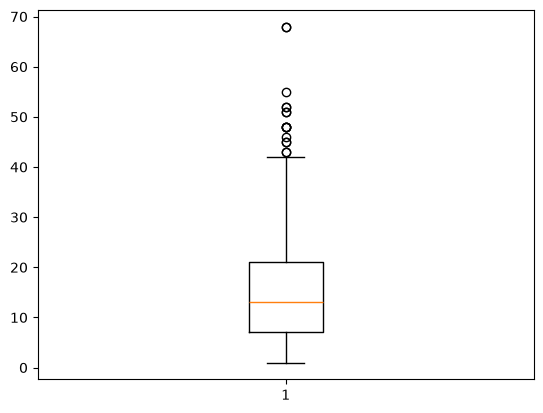

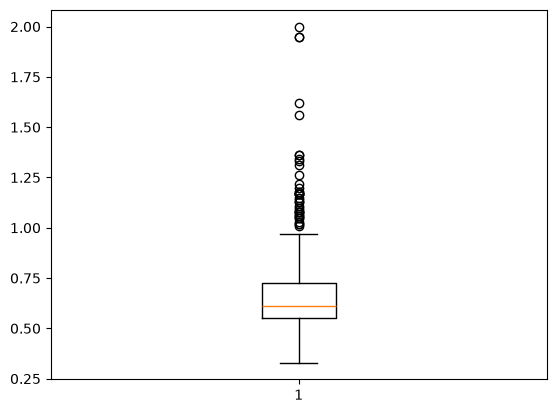

In [143]:
# We'll take a deeper look at residual sugar, chlorides, free sulfur dioxide and sulphates
# since they are much higher than the rest
plt.boxplot(wine_train["residual sugar"])
plt.show()

plt.boxplot(wine_train["chlorides"])
plt.show()

plt.boxplot(wine_train["free sulfur dioxide"])
plt.show()

plt.boxplot(wine_train["sulphates"])
plt.show()

**Discusion**:
there can be made another argument on wether these four should have the limits on their Z_scores heightened to reduce their outlier count. Though this would in turn produce a new variable in the form of ununinform fitting

In [10]:
# Identify rows containing at least one outlier
outlier_rows = outliers.any(axis=1)

# To make sure we aren't removing too much data, resulting in 73 of 835 being flaged and removed  
print(f"Rows to remove: {outlier_rows.sum()}")

# Filtering the data
wine_train_clean = wine_train_sc.loc[~outlier_rows].copy()

Rows to remove: 73


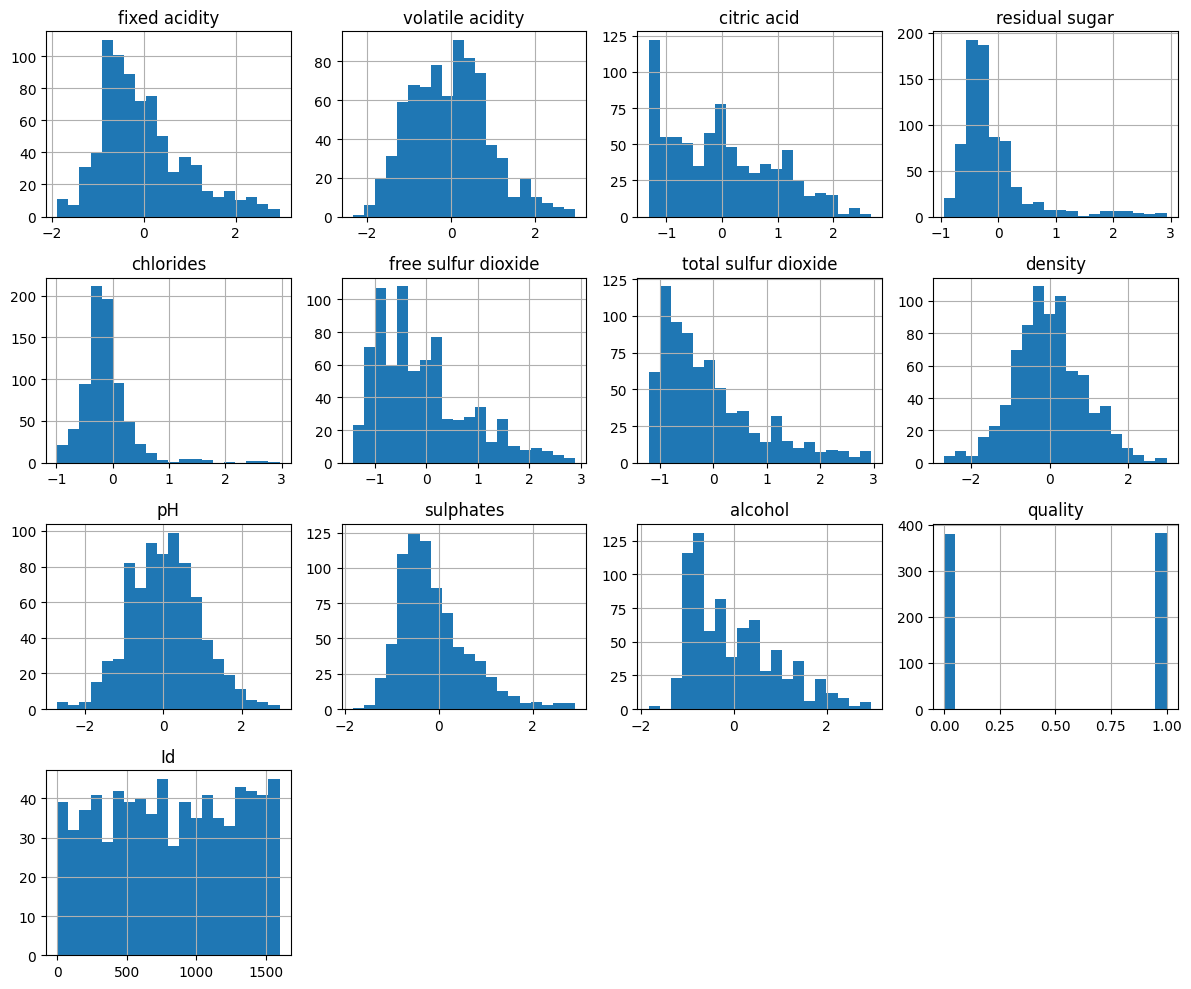

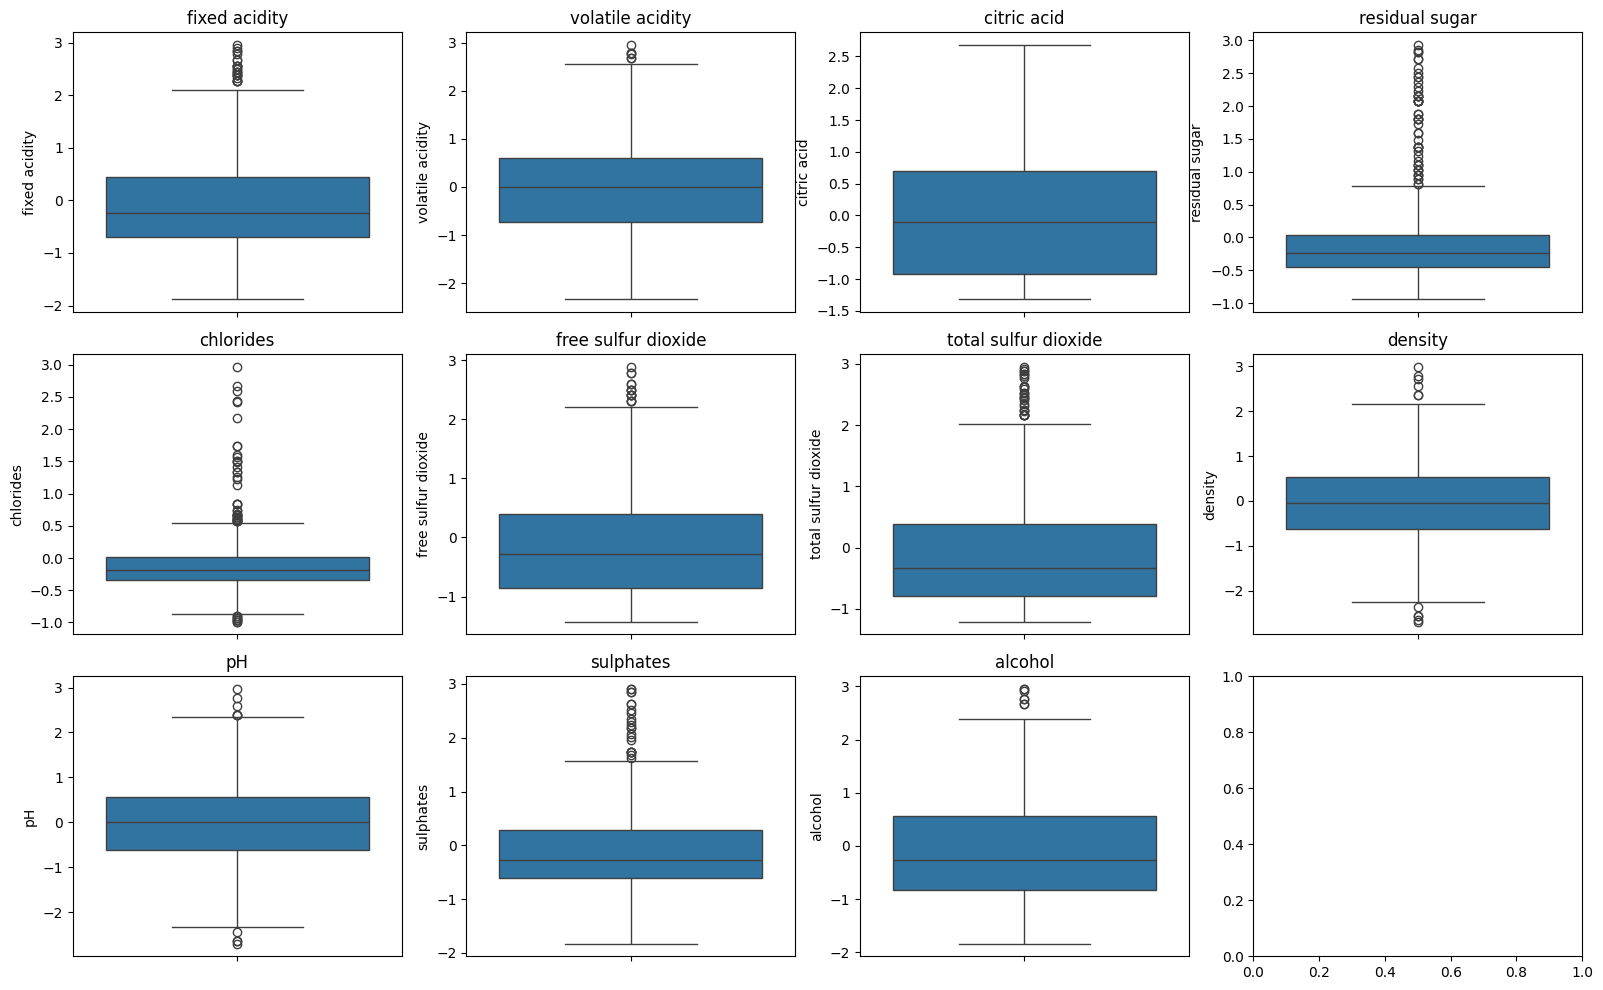

In [11]:
# Displaying the graphs again to visually confirm that the outliers have been removed. No need for thourougnes
wine_train_clean.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

# another set of boxplots
fig, axes = plt.subplots(3, 4, figsize=(16, 10))


for ax, col in zip(axes.flat, features):
    sns.boxplot(data=wine_train_clean, y=col, ax=ax)
    ax.set_title(col)


plt.tight_layout()
plt.show()

### Modelling

In this section we compare five different classifiers from the lectures: (1) Logistic Regression, (2) SVM, (3) k-Nearest Neighbours, (4) decision tree and (5) random forest.

We split our training data to measure accuracy of our models. We cannot do that on the test set, as it does not contain labels that would enable verification.

In this situation, we split the labelled training data into a training part (70%) and a validation part (30%). To ensure accuracy of this method, we repeat the verification for 50 different random splits and take the mean -> for every model.


### Model 1 - Logistic Regression

In [146]:
"""
We define settings for all the classifiers we will be using.
In this way, we want to ensure comparability between the results of our tests.
"""
N_SPLITS = 50           # number of cross-validation splits; 50 gives a stable average
TEST_SIZE = 0.3         # proportion of the dataset to include in the test split

In [147]:
features = [c for c in wine_train.columns if c not in ("quality", "Id")]
print(features)

X = wine_train[features]        # input: the 11 chemical properties of each wine
y = wine_train["quality"]       # answer: 1 = good, 0 = bad
X_test = wine_test[features]    # the Kaggle test wines (no answers), used only at the very end

print("X:", X.shape, " y:", y.shape, " X_test:", X_test.shape)

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
X: (835, 11)  y: (835,)  X_test: (209, 11)


In [148]:
"""
We try our different hyperparameter values. 
Smaller C means strong regularisation and a risk of underfitting.
Larger C means weak regularisation and a risk of overfitting.
"""
params_C_lr = [0.001, 0.01, 0.1, 1, 10, 100]

"""
We will use two different penalties for the logistic regression classifier.
L1 or L2 adds a penalty when the weights get big, which is a form of regularisation.
"""
penalties = ["l1", "l2"]

accArr_train_lr = np.zeros((len(penalties), len(params_C_lr)))
accArr_val_lr = np.zeros((len(penalties), len(params_C_lr)))
accArr_val_std_lr = np.zeros((len(penalties), len(params_C_lr)))


for p_ind, penalty in enumerate(penalties):
    for c_ind, c in enumerate(params_C_lr):

        accTrain_list, accVal_list = [], []
        for rs in range(N_SPLITS):

            # X: the features of each wine (alcohol, pH, etc), which are the model's input
            # y: the answer for each wine (good or bad), which is what the model should predict
            
            X_train, X_val, y_train, y_val = train_test_split(
                X, y, test_size=0.3, random_state=rs, stratify=y)

            sc = StandardScaler()
            sc.fit(X_train)                         # learn mean and std from the training part only
            X_train_sc = sc.transform(X_train)      # apply them to the training part
            X_val_sc = sc.transform(X_val)          # apply the same mean and std to the validation part

            # initialise and train logistic regression with this penalty and C
            lr = LogisticRegression(C=c, penalty=penalty, solver="saga", max_iter=10000)
            lr.fit(X_train_sc, y_train)

            # compute train and validation accuracy and collect them in lists
            accTrain_list.append(lr.score(X_train_sc, y_train))
            accVal_list.append(lr.score(X_val_sc, y_val))

        # average accuracies across all splits
        accArr_train_lr[p_ind, c_ind] = np.mean(accTrain_list)
        accArr_val_lr[p_ind, c_ind] = np.mean(accVal_list)


In [149]:
# the results as a table (rows = penalty, columns = C)
print("Mean validation accuracy:")
print(pd.DataFrame(accArr_val_lr, index=penalties, columns=params_C_lr).round(4))

# only used to check for over/underfitting
print("\nMean train accuracy:")
print(pd.DataFrame(accArr_train_lr, index=penalties, columns=params_C_lr).round(4))


best_params = np.unravel_index(accArr_val_lr.argmax(), accArr_val_lr.shape)

best_lr = {"penalty": penalties[best_params[0]],
           "C": params_C_lr[best_params[1]],
           "acc": round(float(accArr_val_lr[best_params]), 4)}
print("\nBest Logistic Regression:", best_lr)

Mean validation accuracy:
    0.001    0.010    0.100    1.000    10.000   100.000
l1   0.4996   0.7066   0.7441   0.7485   0.7475   0.7473
l2   0.7339   0.7406   0.7461   0.7480   0.7474   0.7473

Mean train accuracy:
    0.001    0.010    0.100    1.000    10.000   100.000
l1   0.5000   0.7016   0.7478   0.7570   0.7585   0.7586
l2   0.7412   0.7488   0.7551   0.7586   0.7586   0.7586

Best Logistic Regression: {'penalty': 'l1', 'C': 1, 'acc': 0.7485}


### Model 2 - Support Vector Machine (SVM)

SVM looks for the boundary between good and bad wines that has the widest possible margin, meaning the largest distance to the nearest wines of each class. Those nearest wines are called support vectors - they decide where the boundary goes.

With a kernel, the SVM can draw curved boundaries instead of only straight lines (logistic regression can only draw straight ones). We first compare three kernels, then tune the best one.

In [150]:
kernels = {
    "linear":             {"kernel": "linear"},
    "polynomial (deg 3)": {"kernel": "poly", "degree": 3},
    "RBF":                {"kernel": "rbf"},
}

for name, settings in kernels.items():
    accVal_list = []

    for rs in range(N_SPLITS):
        X_train, X_val, y_train, y_val = train_test_split(
            X, y, test_size=TEST_SIZE, random_state=rs, stratify=y)

        sc = StandardScaler()
        sc.fit(X_train)
        X_train_sc = sc.transform(X_train)
        X_val_sc = sc.transform(X_val)

        svm_model = SVC(C=1, **settings)
        svm_model.fit(X_train_sc, y_train)
        accVal_list.append(svm_model.score(X_val_sc, y_val))

    print(f"SVM kernel = {name:<20} mean validation accuracy = {np.mean(accVal_list):.4f}")


SVM kernel = linear               mean validation accuracy = 0.7451
SVM kernel = polynomial (deg 3)   mean validation accuracy = 0.7178
SVM kernel = RBF                  mean validation accuracy = 0.7553


In [151]:
"""
Now we tune the hyperparameters of the RBF kernel, which is the best one.
We try every combination of `C` and `gamma`, as in the lecture example.
"""
params_C = np.arange(-1, 2.1, 0.5)
params_gamma = np.array([0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5])

accArr_train = np.zeros((len(params_C), len(params_gamma)))
accArr_val = np.zeros((len(params_C), len(params_gamma)))

for c_ind, c in enumerate(params_C):

    for gamma_ind, gamma_val in enumerate(params_gamma):

        accTrain_list = []
        accVal_list = []

        for rs in range(N_SPLITS):

            X_train, X_val, y_train, y_val = train_test_split(
                X, y, test_size=TEST_SIZE, random_state=rs, stratify=y)

            sc = StandardScaler()
            sc.fit(X_train)

            X_train_sc = sc.transform(X_train)
            X_val_sc = sc.transform(X_val)

            # training SVC with specific values for C and gamma
            SVC_rbf = SVC(kernel="rbf", C=10.**c, gamma=gamma_val, random_state=1)
            SVC_rbf.fit(X_train_sc, y_train)

            # collecting train accuracies in list
            accTrain_list.append(SVC_rbf.score(X_train_sc, y_train))

            # collecting validation accuracies in list
            accVal_list.append(SVC_rbf.score(X_val_sc, y_val))


        accArr_train[c_ind, gamma_ind] = np.mean(accTrain_list)
        accArr_val[c_ind, gamma_ind] = np.mean(accVal_list)

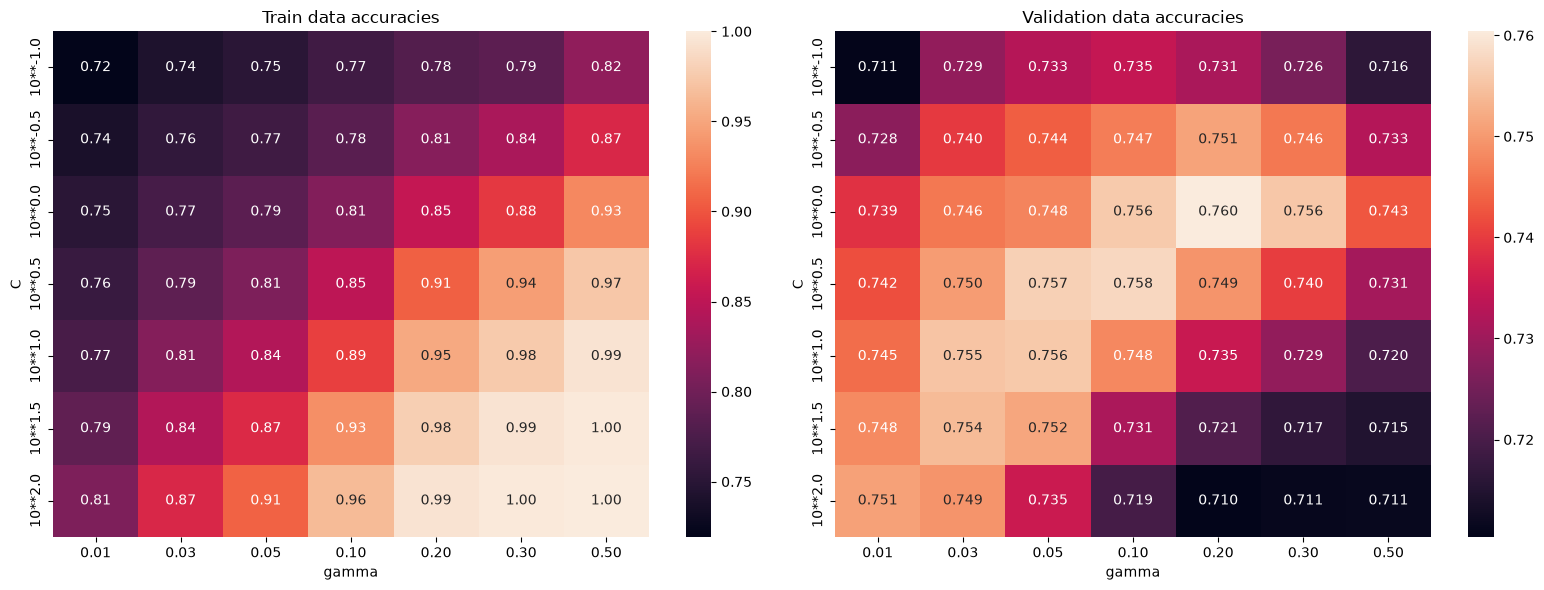

In [152]:
"""
We plot heat maps of train and validation accuracies.
We base our choice of hyperparameters on the validation accuracy, not the training accuracy.
Brighter colors indicate higher accuracy, darker colors indicate lower accuracy.
"""
rowNames = ["10**{0:3.1f}".format(c) for c in params_C]
colNames = ["{0:4.2f}".format(g) for g in params_gamma]

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(pd.DataFrame(accArr_train, index=rowNames, columns=colNames),
            annot=True, fmt=".2f", vmax=1, ax=ax[0])
ax[0].set_xlabel("gamma"); ax[0].set_ylabel("C"); ax[0].set_title("Train data accuracies")

sns.heatmap(pd.DataFrame(accArr_val, index=rowNames, columns=colNames),
            annot=True, fmt=".3f", ax=ax[1])
ax[1].set_xlabel("gamma"); ax[1].set_ylabel("C"); ax[1].set_title("Validation data accuracies")

plt.tight_layout()
plt.show()

In [153]:
# choosing the best hyperparameters based on the validation accuracy
best_params = np.unravel_index(accArr_val.argmax(), accArr_val.shape)

best_svm = {"C": round(float(10.**params_C[best_params[0]]), 3),
            "gamma": float(params_gamma[best_params[1]]),
            "acc": round(float(accArr_val[best_params]), 4)}
print("Best SVM:", best_svm)

Best SVM: {'C': 1.0, 'gamma': 0.2, 'acc': 0.7604}


### Model 3 - K-Nearest Neighbours (KNN)

To classify a new wine, KNN model looks at the *k* most similar wines in the training set (the "nearest neighbours", measured by distance between their features) - if most of them are good, the new wine is predicted good.

The only hyperparameter we tune is *k*, the number of neighbours that we take into account. With small *k* the prediction depends on very few wines, so it follows noise in the data more (risk of overfitting). Large *k* includes more wines, so the prediction becomes more smooth and stable, but if *k* is too large, local patterns are lost (underfitting).

We only use odd values of *k*, because with two classes ("good" or "bad" wine) an odd number of votes can't split evenly, so one class always wins.

In [154]:
best_k = 0              # starting value for best k
best_accuracy = 0       # starting value for best accuracy

k_values = list(range(1, 101, 2))

# lists to store the mean accuracy for every k

knn_train_means = []
knn_val_means = []


for k in k_values:
    
    accuracies = []
    train_accuracies = []

    for r in range(N_SPLITS):

        X_train, X_val, y_train, y_val = train_test_split(
            X, y, test_size=TEST_SIZE, random_state=r, stratify=y)

        # standardising / scaling the data
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)

        # training the KNN model with the current value of k
        knn = KNeighborsClassifier(n_neighbors=k)
        y_pred = knn.fit(X_train_scaled, y_train).predict(X_val_scaled)
        accuracies.append(accuracy_score(y_val, y_pred))

        # checking how well the model does on the wines it was trained on
        train_accuracies.append(knn.score(X_train_scaled, y_train))

    accuracy = np.mean(accuracies)      # mean accuracy across all splits for this k

    knn_val_means.append(accuracy)
    knn_train_means.append(np.mean(train_accuracies))

    # updating the best k and best accuracy if the current k was better
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_k = k


print(f"Best k: {best_k}, Best accuracy during optimization: {best_accuracy:.3f}")

best_knn = {"k": best_k, "acc": round(float(best_accuracy), 4)}
print("Best kNN:", best_knn)


Best k: 55, Best accuracy during optimization: 0.740
Best kNN: {'k': 55, 'acc': 0.7402}


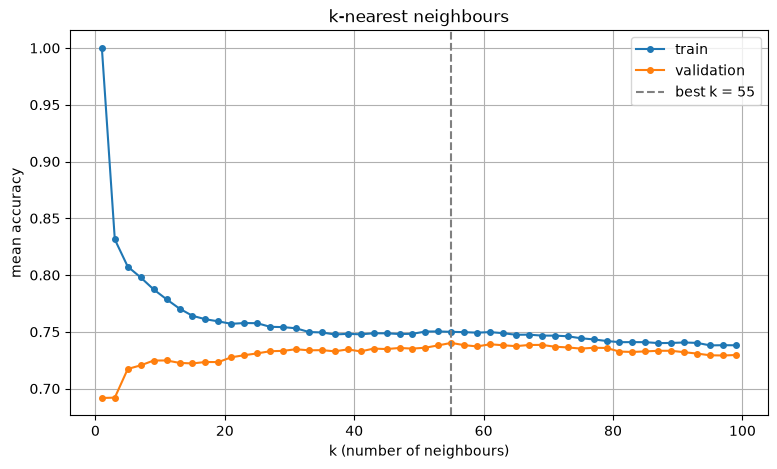

In [155]:
"""
We plot train vs validation accuracy for every k. 
""" 

plt.figure(figsize=(9, 5))
plt.plot(k_values, knn_train_means, marker="o", markersize=4, label="train")
plt.plot(k_values, knn_val_means, marker="o", markersize=4, label="validation")

plt.axvline(best_k, color="grey", linestyle="--", label=f"best k = {best_k}")
plt.xlabel("k (number of neighbours)")
plt.ylabel("mean accuracy")
plt.title("k-nearest neighbours")
plt.legend()
plt.grid(True)
plt.show()

**Discussion**

On the left side, where *k* is very low, train accuracy is very high, but that of validation is low -> we face the problem of overfitting. The lines come closer as *k* grows, the model generalises better, and reaches it's best *k* where the lines are both the closest and the highest. Further right, where we have high *k*, both lines start to drop, as we face underfitting.


### Model 4 - Decision Tree

A decision tree classifies a wine by asking a series of YES / NO questions about its features. 

For this model, we tune two hyperparameters: 
* `max_depth` - the maximum number of questions in a row. Shallow tree is simple risking underfitting. A deep tree can on the other hand create a separate rule for almost every training wine risking overfitting. 
* `criterion` - how the decision tree measures how mixed a group of wines is when choosing the best question: by Gini or Entropy (two different ways of calculating it, usually give similar results).

No scaling is needed. The decision tree only compares one feature at a time, with a threshold, so the size of the numbers does not matter. Scaling would just change the threshold numbers, not the questions or the result.


In [156]:
# the depths we try, from very shallow (2 questions) to unlimited (None)
depths = [2, 3, 4, 5, 6, 8, 10, None]  

criteria = ["gini", "entropy"]

accArr_train_tree = np.zeros((len(criteria), len(depths)))
accArr_val_tree = np.zeros((len(criteria), len(depths)))


for crit_ind, criterion in enumerate(criteria):
    for d_ind, max_depth in enumerate(depths):

        accTrain_list, accVal_list = [], []

        for rs in range(N_SPLITS):

            X_train, X_val, y_train, y_val = train_test_split(
                X, y, test_size=TEST_SIZE, random_state=rs, stratify=y)

            # training the model 
            clf = DecisionTreeClassifier(max_depth=max_depth, criterion=criterion, random_state=42)
            clf.fit(X_train, y_train)

            accTrain_list.append(accuracy_score(y_train, clf.predict(X_train)))
            accVal_list.append(accuracy_score(y_val, clf.predict(X_val)))

        # average over all splits
        accArr_train_tree[crit_ind, d_ind] = np.mean(accTrain_list)
        accArr_val_tree[crit_ind, d_ind] = np.mean(accVal_list)

# we put depths as text, as "None" cannot be used as a table column name or plot label
depth_labels = [str(d) for d in depths]


In [157]:
print("Mean training accuracy:")
print(pd.DataFrame(accArr_train_tree, index=criteria, columns=depth_labels).round(3))

print("\nMean validation accuracy:")
print(pd.DataFrame(accArr_val_tree, index=criteria, columns=depth_labels).round(4))

best_params = np.unravel_index(accArr_val_tree.argmax(), accArr_val_tree.shape)

best_tree = {"criterion": criteria[best_params[0]],
             "max_depth": depths[best_params[1]],
             "acc": round(float(accArr_val_tree[best_params]), 4)}
print("\nBest decision tree:", best_tree)

Mean training accuracy:
             2      3      4      5      6      8     10  None
gini     0.717  0.758  0.799  0.829  0.870  0.938  0.981   1.0
entropy  0.712  0.750  0.786  0.812  0.847  0.911  0.959   1.0

Mean validation accuracy:
              2       3       4       5       6       8      10    None
gini     0.6887  0.7102  0.7313  0.7181  0.7112  0.7063  0.7063  0.7051
entropy  0.6870  0.7033  0.7221  0.7182  0.7086  0.7078  0.7078  0.7060

Best decision tree: {'criterion': 'gini', 'max_depth': 4, 'acc': 0.7313}


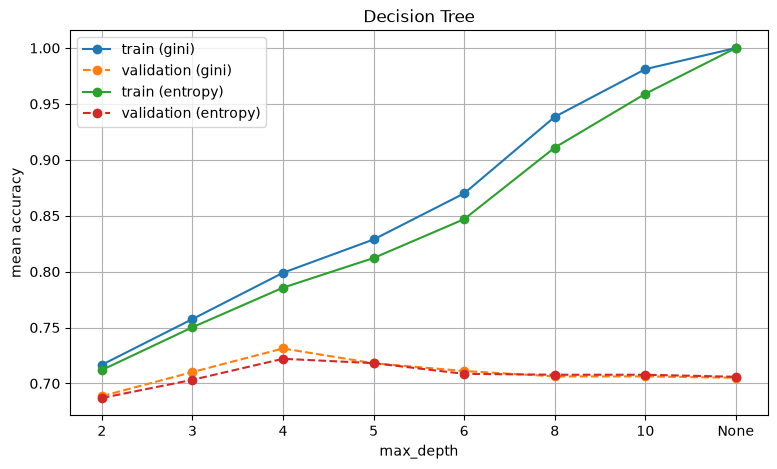

In [158]:
"""
To better understand the performance of our model, we plot the train vs validation accuracy. 
We do it for every combination of criterion and max_depth.
"""
plt.figure(figsize=(9, 5))
for crit_ind, criterion in enumerate(criteria):
    plt.plot(depth_labels, accArr_train_tree[crit_ind], marker="o",
             label=f"train ({criterion})")
    plt.plot(depth_labels, accArr_val_tree[crit_ind], marker="o", linestyle="--",
             label=f"validation ({criterion})")
plt.xlabel("max_depth")
plt.ylabel("mean accuracy")
plt.title("Decision Tree")
plt.legend()
plt.grid(True)
plt.show()


**Discussion**

Each dot is one setting, averaged over 50 splits. The solid lines show accuracy on the wines the tree was trained on, and the dashed lines show accuracy on the validation wines it hasn't seen - the dashed lines tell us how good the model really is. The gap between the lines is a measure of overfitting. At depth 2 it's about 2%, at no limit it's about 30%.

### Model 5 - Random Forest

A random forest is a group of many decision trees that vote. Each tree is made slightly different.

Each tree is trained on a random sample of the training wines. At each question, each tree may only choose from a random subset of the features.

Because the trees are different, they make different mistakes. When they vote, many of those mistakes cancel out. A single tree is very sensitive to small changes in the data, but the average of many trees is much more stable.

We tune two hyperparameters:
* `max_depth` - how deep each tree may grow, as for the single decision tree.
* `n_estimators` - the number of trees. More trees give a more stable vote, but take longer to train. Adding trees does not cause overfitting.

No scaling is needed, for the same reason as for decision trees.


In [159]:
# this code will take long to run

rf_depths = [3, 5, 8, None]
n_estimators_values = [100, 300]

accArr_train_rf = np.zeros((len(n_estimators_values), len(rf_depths)))
accArr_val_rf = np.zeros((len(n_estimators_values), len(rf_depths)))


for n_ind, n in enumerate(n_estimators_values):
    for d_ind, max_depth in enumerate(rf_depths):

        accTrain_list, accVal_list = [], []

        for rs in range(N_SPLITS):

            X_train, X_val, y_train, y_val = train_test_split(
                X, y, test_size=TEST_SIZE, random_state=rs, stratify=y)

            model = RandomForestClassifier(
                n_estimators=n, max_depth=max_depth, criterion="gini", random_state=42, n_jobs=4)
            model.fit(X_train, y_train)

            accTrain_list.append(accuracy_score(y_train, model.predict(X_train)))
            accVal_list.append(accuracy_score(y_val, model.predict(X_val)))

        # average over all splits
        accArr_train_rf[n_ind, d_ind] = np.mean(accTrain_list)
        accArr_val_rf[n_ind, d_ind] = np.mean(accVal_list)

        print(f"n_estimators = {n:<4} max_depth = {str(max_depth):<5} "
              f"train = {accArr_train_rf[n_ind, d_ind]:.4f} validation = {accArr_val_rf[n_ind, d_ind]:.4f}")

# we put depths as text, as "None" cannot be used as a table column name or plot label
rf_depth_labels = [str(d) for d in rf_depths]


n_estimators = 100  max_depth = 3     train = 0.7937 validation = 0.7468
n_estimators = 100  max_depth = 5     train = 0.8620 validation = 0.7625
n_estimators = 100  max_depth = 8     train = 0.9768 validation = 0.7655
n_estimators = 100  max_depth = None  train = 1.0000 validation = 0.7654
n_estimators = 300  max_depth = 3     train = 0.7950 validation = 0.7496
n_estimators = 300  max_depth = 5     train = 0.8634 validation = 0.7626
n_estimators = 300  max_depth = 8     train = 0.9804 validation = 0.7692
n_estimators = 300  max_depth = None  train = 1.0000 validation = 0.7671


In [160]:
print("\nMean validation accuracy:")
print(pd.DataFrame(accArr_val_rf, index=n_estimators_values, columns=rf_depth_labels).round(4))

best_params = np.unravel_index(accArr_val_rf.argmax(), accArr_val_rf.shape)

best_rf = {"n_estimators": n_estimators_values[best_params[0]],
           "max_depth": rf_depths[best_params[1]],
           "acc": round(float(accArr_val_rf[best_params]), 4)}
print("\nBest random forest:", best_rf)


Mean validation accuracy:
          3       5       8    None
100  0.7468  0.7625  0.7655  0.7654
300  0.7496  0.7626  0.7692  0.7671

Best random forest: {'n_estimators': 300, 'max_depth': 8, 'acc': 0.7692}


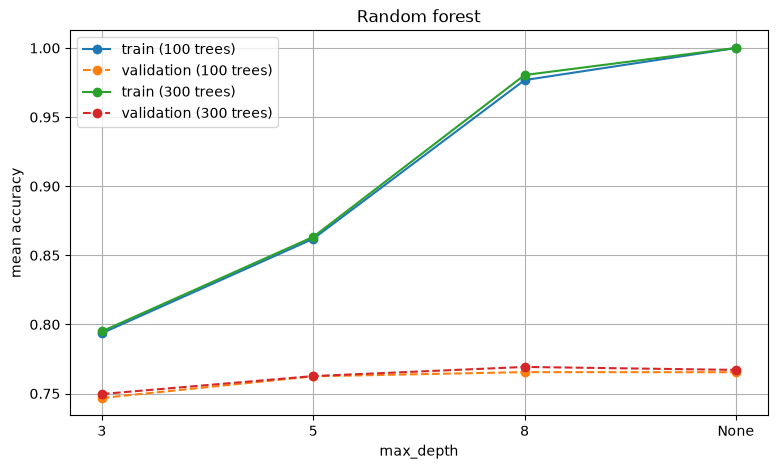

In [161]:
"""
Same as for decision trees, we plot the train vs validation accuracy.
We do it for every combination of n_estimators and max_depth.
"""
plt.figure(figsize=(9, 5))
for n_ind, n in enumerate(n_estimators_values):
    plt.plot(rf_depth_labels, accArr_train_rf[n_ind], marker="o", label=f"train ({n} trees)")
    plt.plot(rf_depth_labels, accArr_val_rf[n_ind], marker="o", linestyle="--",
             label=f"validation ({n} trees)")
plt.xlabel("max_depth")
plt.ylabel("mean accuracy")
plt.title("Random forest")
plt.legend()
plt.grid(True)
plt.show()

### Final evaluation

All five models were evaluated on exactly the same 50 random splits, so we can compare their best settings directly. We choose the model with the highest mean validation accuracy.


In [162]:
# collecting the best result of every model in one table

results = pd.DataFrame({
    "model": ["Logistic regression", "SVM", "KNN", "Decision Tree", "Random Forest"],
    "best settings": [
        f"penalty={best_lr['penalty']}, C={best_lr['C']}",
        f"C={best_svm['C']}, gamma={best_svm['gamma']}",
        f"k={best_knn['k']}",
        f"criterion={best_tree['criterion']}, max_depth={best_tree['max_depth']}",
        f"n_estimators={best_rf['n_estimators']}, max_depth={best_rf['max_depth']}",
    ],
    "mean validation accuracy": [best_lr["acc"], best_svm["acc"], best_knn["acc"],
                                 best_tree["acc"], best_rf["acc"]],
})

# sorting from best to worst, so the best model is in the first row

results = results.sort_values("mean validation accuracy", ascending=False).reset_index(drop=True)
print(results.to_string())

                 model                  best settings  mean validation accuracy
0        Random Forest  n_estimators=300, max_depth=8                    0.7692
1                  SVM               C=1.0, gamma=0.2                    0.7604
2  Logistic regression                penalty=l1, C=1                    0.7485
3                  KNN                           k=55                    0.7402
4        Decision Tree    criterion=gini, max_depth=4                    0.7313


**Discussion**

The random forest has the highest mean validation accuracy (≈ 76.9 %), followed by the SVM (≈ 76.0 %). The two best models are non-linear, so a curved boundary between good and bad wines helps slightly.

We choose the **Random Forest** as our final model.

### Kaggle submission

In [ ]:
"""
We train the chosen model - Random Forest - on ALL of the training data.
During model selection 30% of the data was held back for validation. 
Now that the choice is made, we use all 835 wines, because more data gives a better model.
"""

final_model = RandomForestClassifier(
    n_estimators=best_rf["n_estimators"], max_depth=best_rf["max_depth"], criterion="gini", random_state=42, n_jobs=4)
final_model.fit(X, y)


y_test = final_model.predict(X_test)
y_test = pd.DataFrame(y_test, columns=["quality"])
y_test.index.name = "Id"
y_test[["quality"]].to_csv("submission.csv")

print(y_test.shape)
y_test.head()

(209, 1)


,quality
Id,
0,1
1,1
2,0
3,0
4,0
